In [ ]:
# %% Setup: one colour (green), five shades from dark to light
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle

In [ ]:
# Finds the folder with the 3 clean CSVs: tries "clean" and "facebook clean", here and one level up
FOLDER = next((p for base in (Path.cwd(), Path.cwd().parent) for name in ("clean", "facebook clean")
               if (p := base / name / "daily_performance.csv").exists()), None)
FOLDER = FOLDER.parent if FOLDER else Path.cwd() / "clean"      # set this by hand if it still fails
print("Reading CSVs from:", FOLDER)
SAVE = False                                # True = also save each dashboard as a PNG

G1, G2, G3, G4, G5 = "#14532D", "#15803D", "#22C55E", "#86EFAC", "#DCFCE7"
INK, MUTED, GRID = "#1F2937", "#6B7280", "#E5E7EB"
SHADES = [G1, G2, G3, G4, G5]
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "axes.titlepad": 10,
    "text.color": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "legend.frameon": False, "font.size": 10,
})
thousands = mtick.FuncFormatter(lambda x, _: f"{x:,.0f}")


In [ ]:
# Functions for dashboard layout and charts
def page(title):
    """Blank dashboard: row 0 = KPI cards, rows 1-2 = charts."""
    fig = plt.figure(figsize=(16, 10), layout="constrained")
    fig.suptitle(title, x=0.005, ha="left", fontsize=20, fontweight="bold", color=G1)
    return fig, fig.add_gridspec(3, 4, height_ratios=[0.4, 1, 1])

def kpi(ax, label, value, note):
    ax.axis("off")
    ax.add_patch(Rectangle((0, 0), 1, 1, transform=ax.transAxes, color=G5))
    ax.add_patch(Rectangle((0, 0), 0.018, 1, transform=ax.transAxes, color=G2))
    ax.text(0.07, 0.76, label.upper(), transform=ax.transAxes, fontsize=9, color=MUTED, fontweight="bold")
    ax.text(0.07, 0.34, value, transform=ax.transAxes, fontsize=26, color=G1, fontweight="bold")
    ax.text(0.07, 0.10, note, transform=ax.transAxes, fontsize=9)

def hbar(ax, labels, values, fmt="{:,.0f}"):
    """Horizontal bars, label above each bar, biggest in dark green."""
    y = np.arange(len(values))[::-1]
    ax.barh(y, values, height=0.48, color=[G1] + [G3] * (len(values) - 1))
    for yi, label, v in zip(y, labels, values):
        ax.text(0, yi + 0.34, label, fontsize=9, va="bottom")
        ax.text(v, yi, " " + fmt.format(v), fontsize=9, fontweight="bold", va="center")
    ax.set(yticks=[], ylim=(-0.6, len(values) - 0.1), xlim=(0, max(values) * 1.2))
    ax.grid(axis="y", visible=False)

def donut(ax, values, labels, shades, centre):
    _, _, texts = ax.pie(values, labels=labels, colors=shades, startangle=90, counterclock=False,
                         autopct=lambda p: f"{p:.0f}%" if p >= 4 else "", pctdistance=0.78,
                         wedgeprops=dict(width=0.42, edgecolor="white", linewidth=3), textprops=dict(fontsize=9))
    for text, c in zip(texts, shades):
        r, g, b = to_rgb(c)
        text.set(color="white" if 0.3 * r + 0.59 * g + 0.11 * b < 0.5 else INK, fontweight="bold")
    ax.text(0, 0, centre, ha="center", va="center", fontsize=13, fontweight="bold", color=G1)

def months(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

def show(fig, name):
    if SAVE:
        fig.savefig(f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

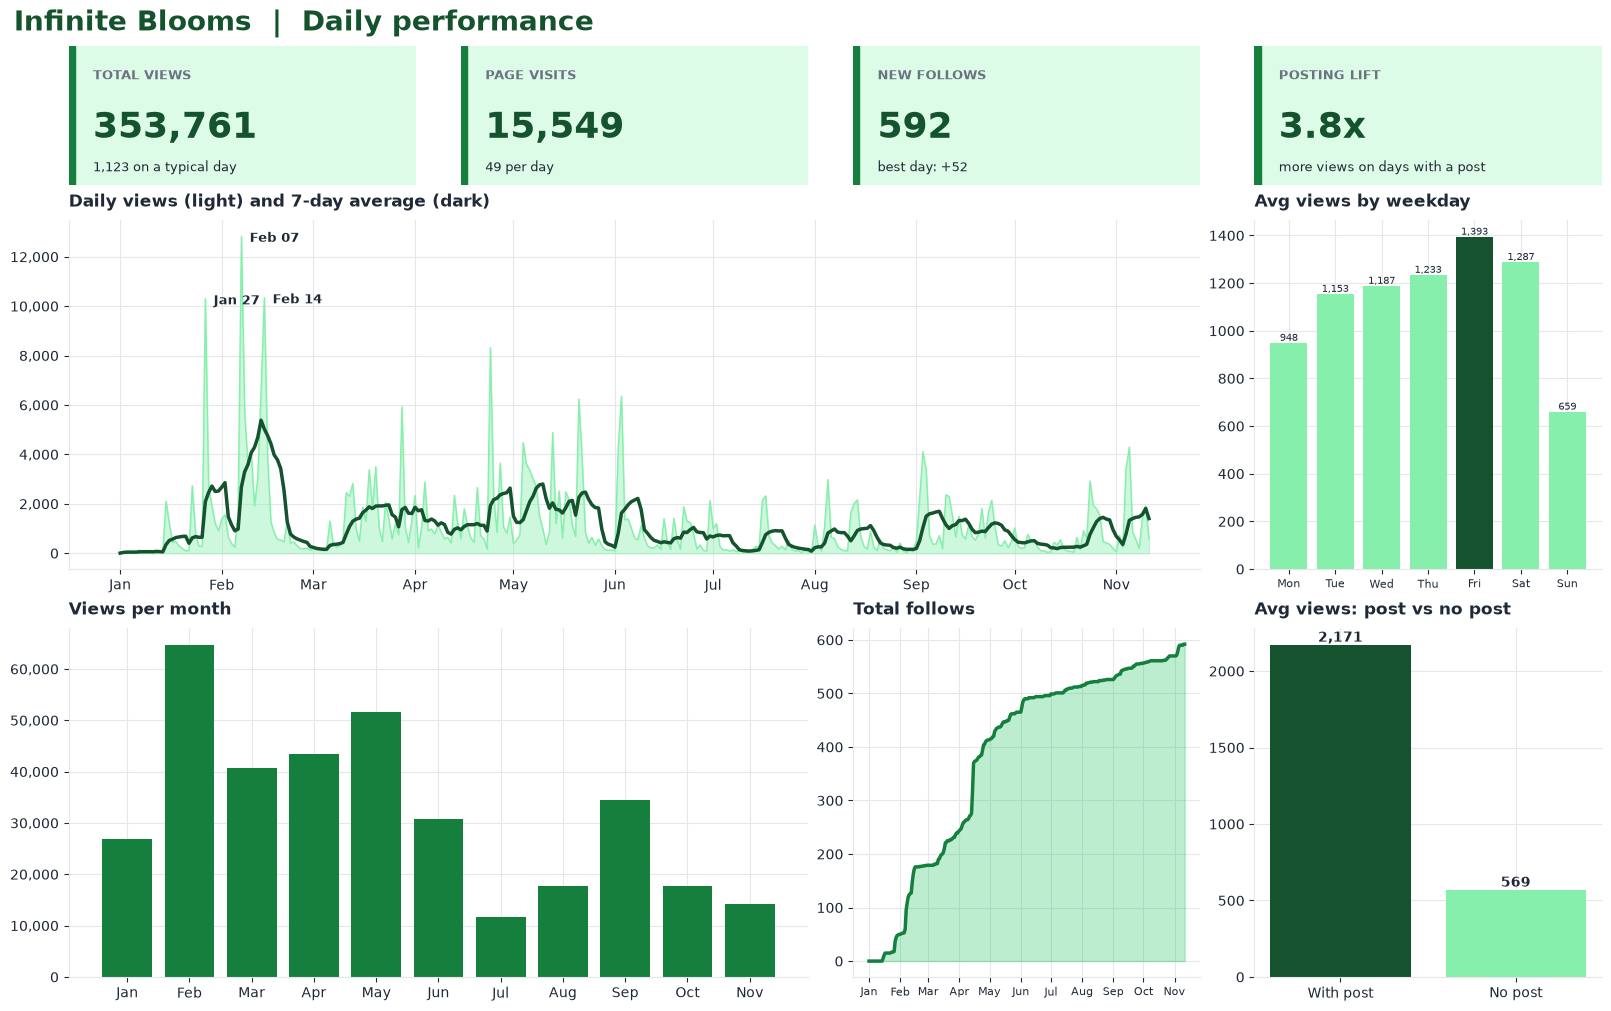

In [3]:
# DASHBOARD 1: daily performance
daily = pd.read_csv(FOLDER / "daily_performance.csv", parse_dates=["date"])
by_day = daily.groupby("weekday")["views"].mean().reindex(DAYS)
monthly = daily.groupby(daily["date"].dt.strftime("%b"), sort=False)["views"].sum()
post_day = daily.groupby(daily["posts_published"] > 0)["views"].mean()      # False / True
lift = post_day[True] / post_day[False]

fig, gs = page("Infinite Blooms  |  Daily performance")
kpi(fig.add_subplot(gs[0, 0]), "Total views", f"{daily['views'].sum():,}", f"{daily['views'].mean():,.0f} on a typical day")
kpi(fig.add_subplot(gs[0, 1]), "Page visits", f"{daily['visits'].sum():,}", f"{daily['visits'].mean():,.0f} per day")
kpi(fig.add_subplot(gs[0, 2]), "New follows", f"{daily['follows'].sum():,}", f"best day: +{daily['follows'].max()}")
kpi(fig.add_subplot(gs[0, 3]), "Posting lift", f"{lift:.1f}x", "more views on days with a post")

ax = fig.add_subplot(gs[1, :3])
ax.fill_between(daily["date"], daily["views"], color=G4, alpha=0.4)
ax.plot(daily["date"], daily["views"], color=G4, linewidth=1)
ax.plot(daily["date"], daily["views_7day_avg"], color=G1, linewidth=2.5)
for _, r in daily.nlargest(3, "views").iterrows():
    ax.annotate(f"{r['date']:%b %d}", (r["date"], r["views"]), xytext=(6, -4), textcoords="offset points", fontsize=9, fontweight="bold")
ax.yaxis.set_major_formatter(thousands)
months(ax)
ax.set_title("Daily views (light) and 7-day average (dark)")

ax = fig.add_subplot(gs[1, 3])
ax.bar([d[:3] for d in DAYS], by_day, color=[G1 if v == by_day.max() else G4 for v in by_day])
for i, v in enumerate(by_day):
    ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=7)
ax.set_title("Avg views by weekday")
ax.tick_params(axis="x", labelsize=8)

ax = fig.add_subplot(gs[2, :2])
ax.bar(monthly.index, monthly, color=G2)
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Views per month")

ax = fig.add_subplot(gs[2, 2])
ax.fill_between(daily["date"], daily["cumulative_follows"], color=G3, alpha=0.3)
ax.plot(daily["date"], daily["cumulative_follows"], color=G2, linewidth=2.5)
months(ax)
ax.tick_params(axis="x", labelsize=8)
ax.set_title("Total follows")

ax = fig.add_subplot(gs[2, 3])
ax.bar(["With post", "No post"], [post_day[True], post_day[False]], color=[G1, G4])
for i, v in enumerate([post_day[True], post_day[False]]):
    ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontweight="bold")
ax.set_title("Avg views: post vs no post")
show(fig, "daily_dashboard")

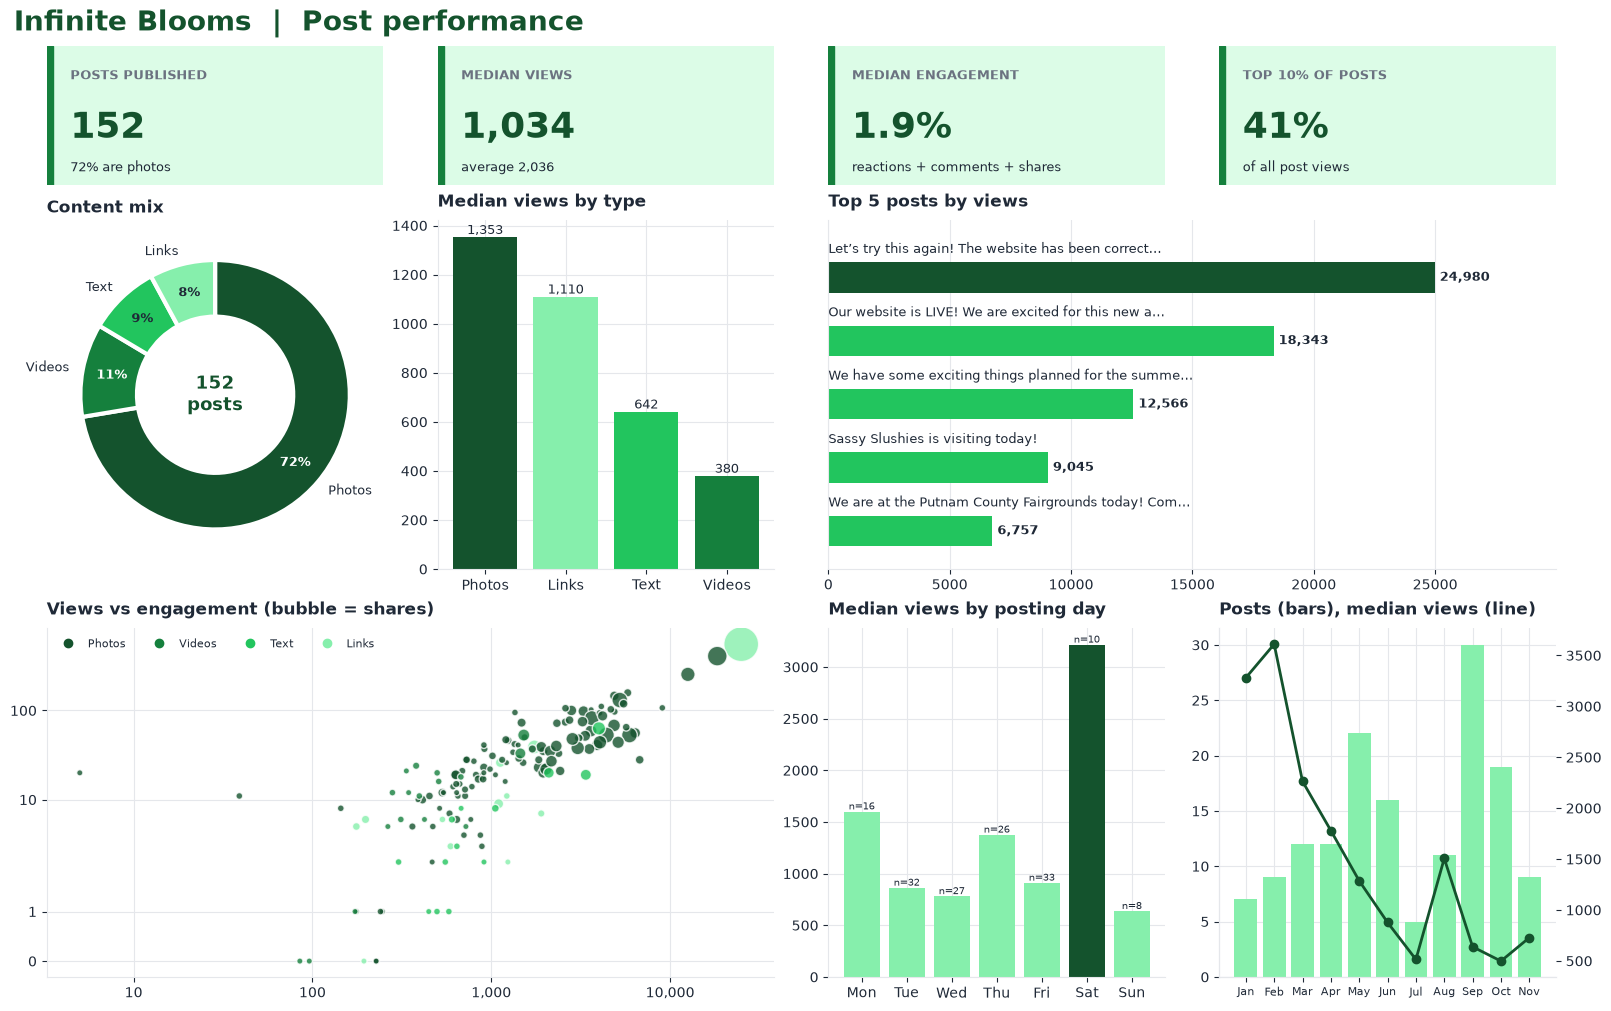

In [4]:
#DASHBOARD 2: post performance
posts = pd.read_csv(FOLDER / "post_performance.csv", parse_dates=["publish_date"], dtype={"post_id": str})
posts["title"] = posts["title"].fillna("")
types = posts["post_type"].value_counts()
shade = dict(zip(types.index, SHADES))
med_views = posts.groupby("post_type")["views"].median().sort_values(ascending=False)
by_weekday = posts.groupby("weekday")["views"].agg(["median", "count"]).reindex(DAYS)
rhythm = posts.groupby("month").agg(posts=("post_id", "count"), views=("views", "median"))
top10_share = posts.nlargest(len(posts) // 10, "views")["views"].sum() / posts["views"].sum()

fig, gs = page("Infinite Blooms  |  Post performance")
kpi(fig.add_subplot(gs[0, 0]), "Posts published", f"{len(posts)}", f"{types.iloc[0] / len(posts):.0%} are {types.index[0].lower()}")
kpi(fig.add_subplot(gs[0, 1]), "Median views", f"{posts['views'].median():,.0f}", f"average {posts['views'].mean():,.0f}")
kpi(fig.add_subplot(gs[0, 2]), "Median engagement", f"{posts['engagement_rate_pct'].median():.1f}%", "reactions + comments + shares")
kpi(fig.add_subplot(gs[0, 3]), "Top 10% of posts", f"{top10_share:.0%}", "of all post views")

donut(fig.add_subplot(gs[1, 0]), types, types.index, [shade[t] for t in types.index], f"{len(posts)}\nposts")
fig.axes[-1].set_title("Content mix")

ax = fig.add_subplot(gs[1, 1])
ax.bar(med_views.index, med_views, color=[shade[t] for t in med_views.index])
for i, v in enumerate(med_views):
    ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
ax.set_title("Median views by type")

top5 = posts.nlargest(5, "views")
ax = fig.add_subplot(gs[1, 2:])
clean = top5["title"].str.replace(r"[^\u0000-\u24FF]", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()   # emoji can't be drawn
hbar(ax, [t[:50] + ("…" if len(t) > 50 else "") for t in clean], top5["views"])
ax.set_title("Top 5 posts by views")

ax = fig.add_subplot(gs[2, :2])
for t, g in posts.groupby("post_type"):
    ax.scatter(g["views"], g["engagement"], s=20 + g["shares"] * 4, color=shade[t], alpha=0.8, edgecolor="white", label=t)
ax.set(xscale="symlog", yscale="symlog")
ax.xaxis.set_major_formatter(thousands)
ax.yaxis.set_major_formatter(thousands)
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=t) for t, c in shade.items()], ncol=4, loc="upper left", fontsize=8)
ax.set_title("Views vs engagement (bubble = shares)")

ax = fig.add_subplot(gs[2, 2])
ax.bar([d[:3] for d in DAYS], by_weekday["median"], color=[G1 if v == by_weekday["median"].max() else G4 for v in by_weekday["median"]])
for i, (v, n) in enumerate(zip(by_weekday["median"], by_weekday["count"])):
    ax.text(i, v, f"n={n}", ha="center", va="bottom", fontsize=7)
ax.set_title("Median views by posting day")

ax = fig.add_subplot(gs[2, 3])
labels = pd.to_datetime(rhythm.index).strftime("%b")
ax.bar(labels, rhythm["posts"], color=G4)
ax.tick_params(axis="x", labelsize=8)
ax2 = ax.twinx()
ax2.plot(labels, rhythm["views"], color=G1, marker="o", linewidth=2)
ax2.grid(False)
ax2.spines["right"].set_visible(False)
ax.set_title("Posts (bars), median views (line)")
show(fig, "posts_dashboard")

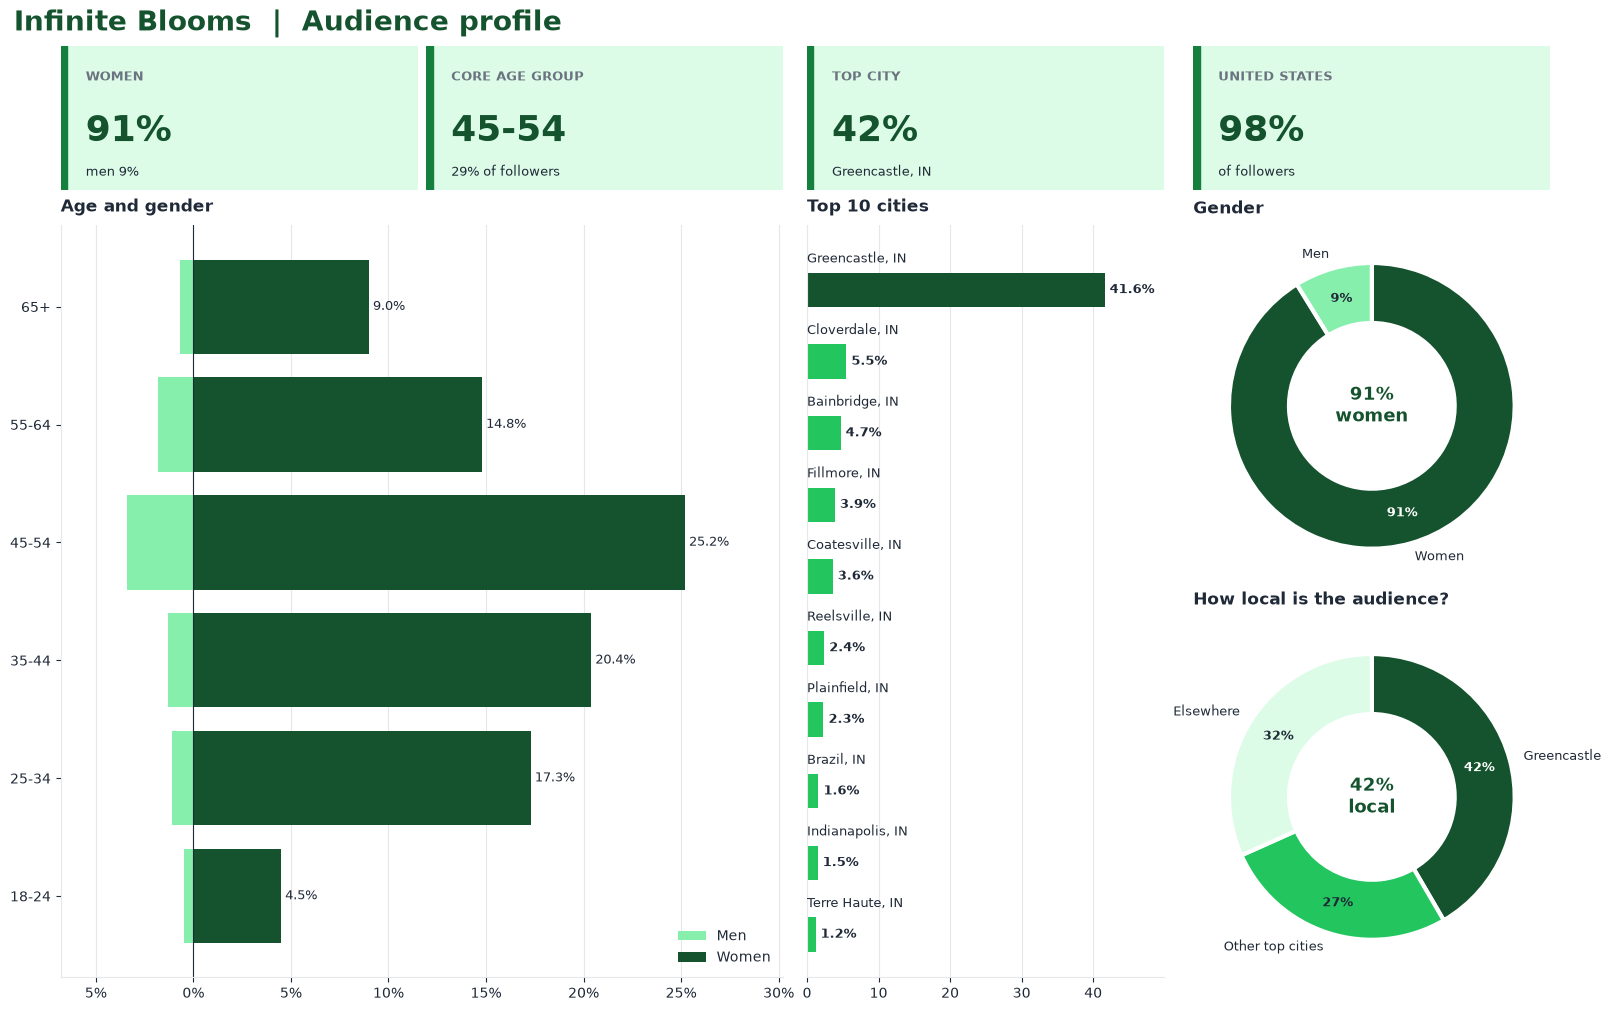

In [5]:
#DASHBOARD 3: audience profile
audience = pd.read_csv(FOLDER / "audience_profile.csv")
age = audience[audience["dimension"] == "age_gender"].pivot(index="age", columns="gender", values="pct")
cities = audience[audience["dimension"] == "city"].sort_values("pct", ascending=False)
countries = audience[audience["dimension"] == "country"].set_index("category")["pct"]
women, men = age["women"].sum(), age["men"].sum()
core = (age["women"] + age["men"]).idxmax()
home = cities.iloc[0]

fig, gs = page("Infinite Blooms  |  Audience profile")
kpi(fig.add_subplot(gs[0, 0]), "Women", f"{women:.0f}%", f"men {men:.0f}%")
kpi(fig.add_subplot(gs[0, 1]), "Core age group", core, f"{age.loc[core].sum():.0f}% of followers")
kpi(fig.add_subplot(gs[0, 2]), "Top city", f"{home['pct']:.0f}%", home["category"])
kpi(fig.add_subplot(gs[0, 3]), "United States", f"{countries.get('United States', np.nan):.0f}%", "of followers")

ax = fig.add_subplot(gs[1:, :2])
ax.barh(age.index, -age["men"], color=G4, label="Men")
ax.barh(age.index, age["women"], color=G1, label="Women")
for i, w in enumerate(age["women"]):
    ax.text(w, i, f" {w:.1f}%", va="center", fontsize=9)
ax.axvline(0, color=INK, linewidth=0.8)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{abs(x):.0f}%"))
ax.set_xlim(-age["men"].max() * 2, age["women"].max() * 1.2)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Age and gender")

ax = fig.add_subplot(gs[1:, 2])
hbar(ax, cities["category"], cities["pct"], fmt="{:.1f}%")
ax.set_title("Top 10 cities")

donut(fig.add_subplot(gs[1, 3]), [women, men], ["Women", "Men"], [G1, G4], f"{women:.0f}%\nwomen")
fig.axes[-1].set_title("Gender")

other = cities["pct"].sum() - home["pct"]
donut(fig.add_subplot(gs[2, 3]), [home["pct"], other, max(0, 100 - home["pct"] - other)],
      [home["category"].split(",")[0], "Other top cities", "Elsewhere"], [G1, G3, G5], f"{home['pct']:.0f}%\nlocal")
fig.axes[-1].set_title("How local is the audience?")
show(fig, "audience_dashboard")